<a href="https://colab.research.google.com/github/ahmed-id-machiche/deep_learning_tps/blob/main/TP3_GD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.utils import to_categorical
import tensorflow as tf

# 1 Load the Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# 2 Split into Training (70%), Validation (15%), and Test (15%) FIRST
# First split: 70% train, 30% temp
X_train, X_temp, y_train_raw, y_temp_raw = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Second split: divide the 30% temp equally into 15% val and 15% test
X_val, X_test, y_val_raw, y_test_raw = train_test_split(
    X_temp, y_temp_raw, test_size=0.50, random_state=42, stratify=y_temp_raw
)

# 3 Normalize features properly (Fit ONLY on X_train to prevent data leakage)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# 4 One-hot encode the labels AFTER splitting
y_train = to_categorical(y_train_raw, num_classes=3)
y_val = to_categorical(y_val_raw, num_classes=3)
y_test = to_categorical(y_test_raw, num_classes=3)

print(f"Training set shape:   {X_train.shape}")
print(f"Validation set shape: {X_val.shape}")
print(f"Test set shape:       {X_test.shape}")

Training set shape:   (105, 4)
Validation set shape: (22, 4)
Test set shape:       (23, 4)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import SGD

def create_model(learning_rate=0.01):
    model = Sequential([
        Input(shape=(4,)),                 # Input layer = 4 features
        Dense(10, activation='relu'),      # Hidden layer = 10 neurons, ReLU
        Dense(3, activation='softmax')     # Output layer = 3 classes, Softmax
    ])

    # Compile with SGD optimizer and categorical crossentropy loss
    optimizer = SGD(learning_rate=learning_rate)
    model.compile(
        optimizer=optimizer,
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# Quick check of the architecture
sample_model = create_model()
sample_model.summary()

Model: "sequential_50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_100 (Dense)               │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_101 (Dense)               │ (None, 3)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 83 (332.00 B)

 Trainable params: 83 (332.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
epochs = 100
learning_rate = 0.01

# Dictionaries to store histories and models across cells
histories = {}
trained_models = {}

In [ ]:
# Train using the entire training set for each update
print("Training with BGD (batch_size = All)...")
model_bgd = create_model(learning_rate=learning_rate)

history_bgd = model_bgd.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=epochs,
    batch_size=len(X_train),  # All samples at once
    verbose=0
)

histories["BGD (batch_size=All)"] = history_bgd
trained_models["BGD (batch_size=All)"] = model_bgd

print(f"BGD finished. Final Train Loss: {history_bgd.history['loss'][-1]:.4f} | Final Val Loss: {history_bgd.history['val_loss'][-1]:.4f}")

Training with BGD (batch_size = All)...
BGD finished. Final Train Loss: 0.6064 | Final Val Loss: 0.6641


In [ ]:
# Update weights 1 sample at a time
print("Training with SGD (batch_size = 1)...")
model_sgd = create_model(learning_rate=learning_rate)

history_sgd = model_sgd.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=epochs,
    batch_size=1,  # 1 sample at a time
    verbose=0
)

histories["SGD (batch_size=1)"] = history_sgd
trained_models["SGD (batch_size=1)"] = model_sgd

print(f"SGD finished. Final Train Loss: {history_sgd.history['loss'][-1]:.4f} | Final Val Loss: {history_sgd.history['val_loss'][-1]:.4f}")

Training with SGD (batch_size = 1)...
SGD finished. Final Train Loss: 0.0373 | Final Val Loss: 0.1753


In [ ]:
# Update weights using small batches of 16
print("Training with MBGD (batch_size = 16)...")
model_mbgd = create_model(learning_rate=learning_rate)

history_mbgd = model_mbgd.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=epochs,
    batch_size=16,  # Small batches
    verbose=0
)

histories["MBGD (batch_size=16)"] = history_mbgd
trained_models["MBGD (batch_size=16)"] = model_mbgd

print(f"MBGD finished. Final Train Loss: {history_mbgd.history['loss'][-1]:.4f} | Final Val Loss: {history_mbgd.history['val_loss'][-1]:.4f}")

Training with MBGD (batch_size = 16)...
MBGD finished. Final Train Loss: 0.2785 | Final Val Loss: 0.3455


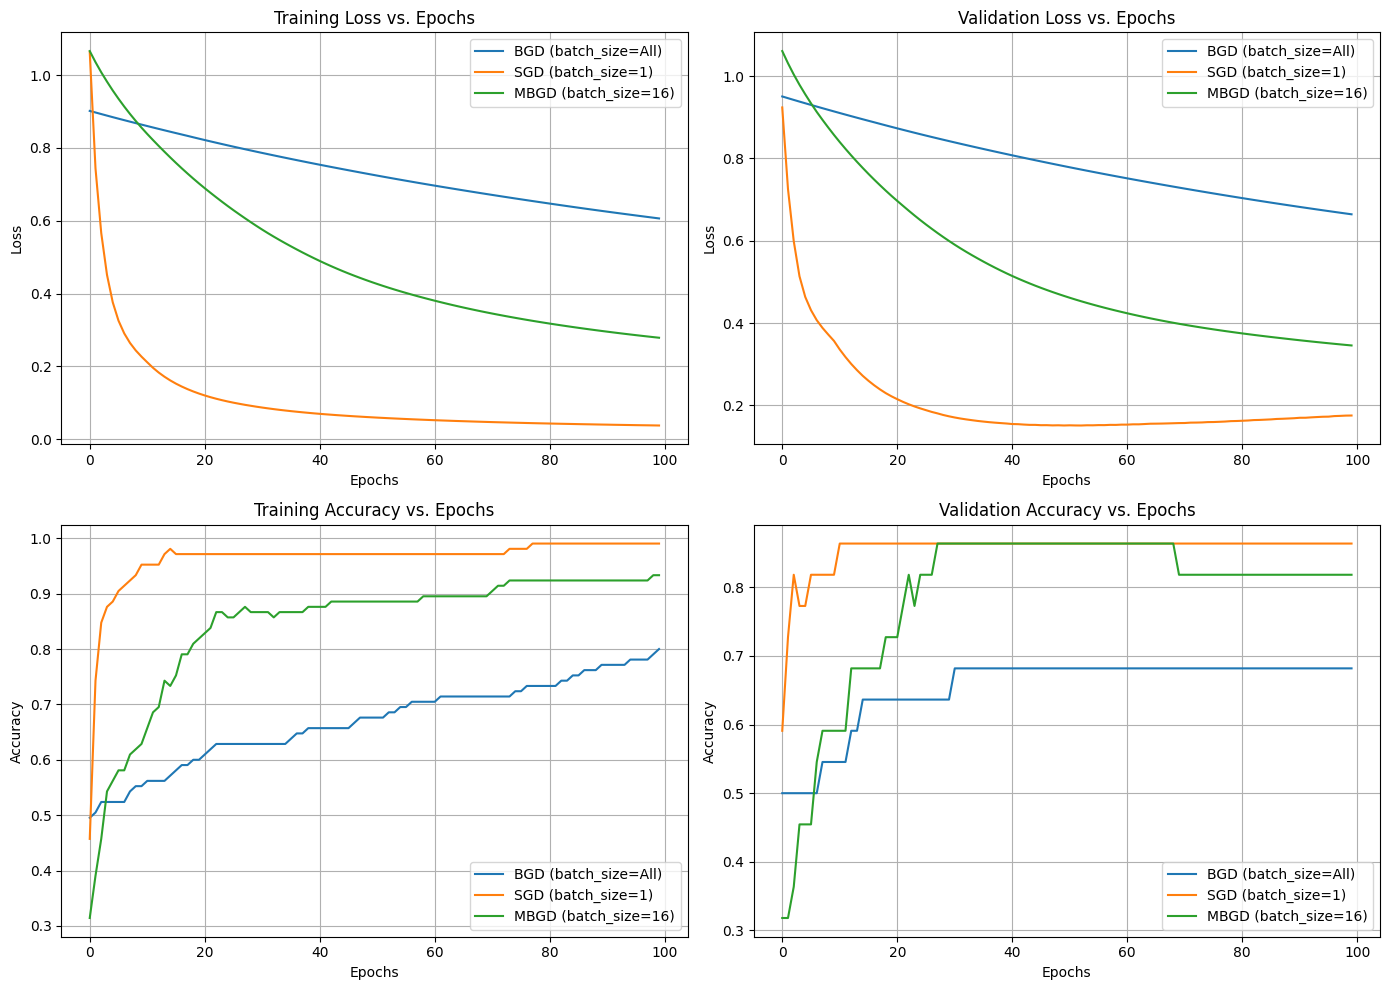

In [ ]:
plt.figure(figsize=(14, 10))

# Subplot 1: Training Loss
plt.subplot(2, 2, 1)
for name, history in histories.items():
    plt.plot(history.history['loss'], label=name)
plt.title('Training Loss vs. Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Subplot 2: Validation Loss
plt.subplot(2, 2, 2)
for name, history in histories.items():
    plt.plot(history.history['val_loss'], label=name)
plt.title('Validation Loss vs. Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Subplot 3: Training Accuracy
plt.subplot(2, 2, 3)
for name, history in histories.items():
    plt.plot(history.history['accuracy'], label=name)
plt.title('Training Accuracy vs. Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Subplot 4: Validation Accuracy
plt.subplot(2, 2, 4)
for name, history in histories.items():
    plt.plot(history.history['val_accuracy'], label=name)
plt.title('Validation Accuracy vs. Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

,Method,Test Loss,Test Accuracy (%)
0,BGD (batch_size=All),0.6529,73.91%
1,SGD (batch_size=1),0.0970,95.65%
2,MBGD (batch_size=16),0.3869,82.61%


In [ ]:
import pandas as pd

# Evaluate each trained model on the test set
evaluation_data = []

for name, model in trained_models.items():
    test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
    evaluation_data.append({
        "Method": name,
        "Test Loss": f"{test_loss:.4f}",
        "Test Accuracy (%)": f"{test_accuracy * 100:.2f}%"
    })

# Convert to a DataFrame
df_results = pd.DataFrame(evaluation_data)

# Apply custom styling to make it big and clear
styled_table = df_results.style.set_table_styles([
    # Style for table headers (th) and data cells (td)
    {'selector': 'th, td', 'props': [('font-size', '16px'), ('padding', '12px 20px'), ('text-align', 'center')]},
    # Style specifically for headers to make them bold
    {'selector': 'th', 'props': [('font-weight', 'bold'), ('background-color', 'gray')]}
])

# Display the large, styled table
display(styled_table)

,Method,Test Loss,Test Accuracy (%)
0,BGD (batch_size=All),0.6529,73.91%
1,SGD (batch_size=1),0.0970,95.65%
2,MBGD (batch_size=16),0.3869,82.61%


In [ ]:
print("--- Test Set Evaluation ---")
for name, model in trained_models.items():
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
    print(f"{name:22s} -> Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc * 100:.2f}%")

--- Test Set Evaluation ---
BGD (batch_size=All)   -> Test Loss: 0.6529 | Test Accuracy: 73.91%
SGD (batch_size=1)     -> Test Loss: 0.0970 | Test Accuracy: 95.65%
MBGD (batch_size=16)   -> Test Loss: 0.3869 | Test Accuracy: 82.61%


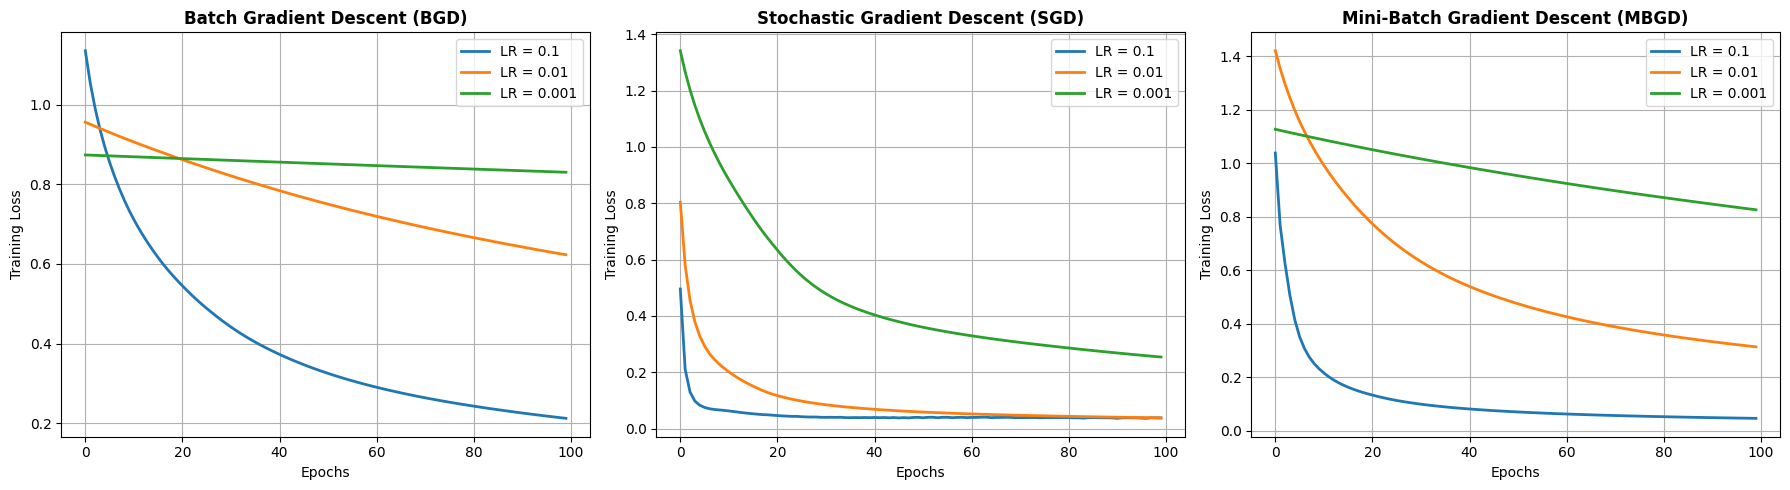

In [ ]:
import matplotlib.pyplot as plt

# Define the learning rates to test and the batch size mappings
learning_rates = [0.1, 0.01, 0.001]
batch_configs = {
    "Batch Gradient Descent (BGD)": len(X_train),
    "Stochastic Gradient Descent (SGD)": 1,
    "Mini-Batch Gradient Descent (MBGD)": 16
}

epochs = 100

# Create a figure with 3 subplots side-by-side (one for each GD type)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (gd_name, b_size) in enumerate(batch_configs.items()):
    ax = axes[idx]

    for lr in learning_rates:
        # Create a fresh model with the specific learning rate
        model = create_model(learning_rate=lr)

        # Train the model
        history = model.fit(
            X_train, y_train,
            validation_data=(X_val, y_val),
            epochs=epochs,
            batch_size=b_size,
            verbose=0
        )

        # Plot the training loss curve for this learning rate
        ax.plot(history.history['loss'], label=f'LR = {lr}', linewidth=2)

    ax.set_title(f'{gd_name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Epochs')
    ax.set_ylabel('Training Loss')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

Training Mini-Batch GD with different batch sizes...

Training with batch_size = 8...
Training with batch_size = 16...
Training with batch_size = 32...

Training complete! Generating comparison plots...


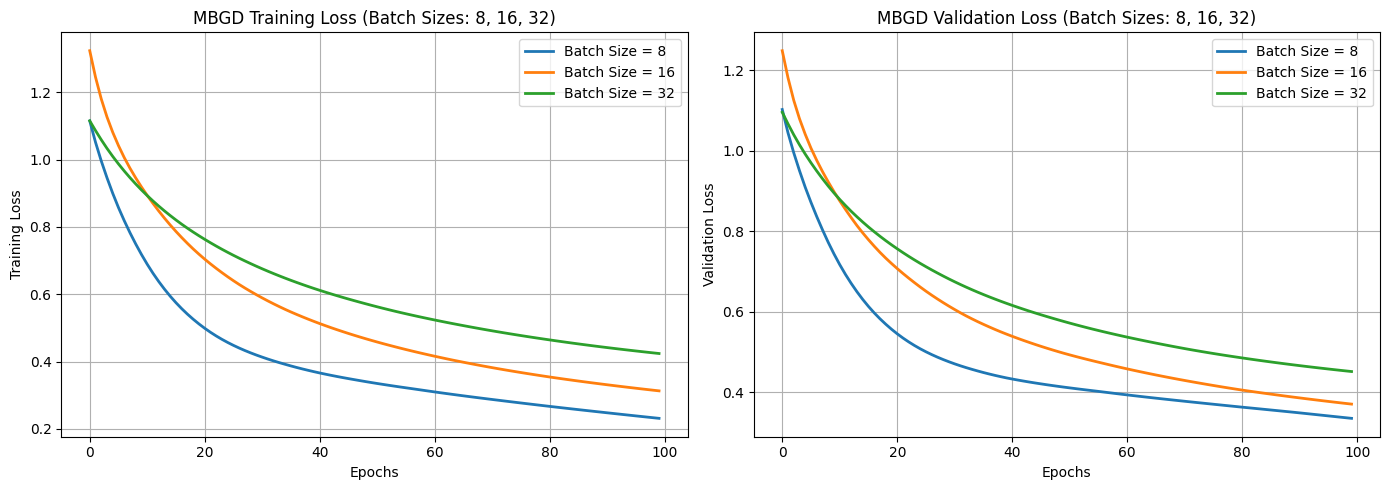

In [ ]:
import matplotlib.pyplot as plt

# Define the batch sizes to test for Mini-Batch GD
batch_sizes_to_test = [8, 16, 32]
learning_rate = 0.01
epochs = 100

mbgd_histories = {}

print("Training Mini-Batch GD with different batch sizes...\n")

for b_size in batch_sizes_to_test:
    print(f"Training with batch_size = {b_size}...")
    model = create_model(learning_rate=learning_rate)

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=b_size,
        verbose=0
    )

    mbgd_histories[f"Batch Size = {b_size}"] = history

print("\nTraining complete! Generating comparison plots...")

# Plot the results side-by-side
plt.figure(figsize=(14, 5))

# Subplot 1: Training Loss
plt.subplot(1, 2, 1)
for name, history in mbgd_histories.items():
    plt.plot(history.history['loss'], label=name, linewidth=2)
plt.title('MBGD Training Loss (Batch Sizes: 8, 16, 32)')
plt.xlabel('Epochs')
plt.ylabel('Training Loss')
plt.legend()
plt.grid(True)

# Subplot 2: Validation Loss
plt.subplot(1, 2, 2)
for name, history in mbgd_histories.items():
    plt.plot(history.history['val_loss'], label=name, linewidth=2)
plt.title('MBGD Validation Loss (Batch Sizes: 8, 16, 32)')
plt.xlabel('Epochs')
plt.ylabel('Validation Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np

# Define configurations matching your sketch structure
gd_methods = {
    "BGD": len(X_train),
    "SGD": 1,
    "MBGD": 16
}
learning_rates = [0.1, 0.01, 0.001]
epochs = 100

# Dictionary to hold the data for our MultiIndex table
matrix_data = {}

print("Running all experiments to build the matrix table...\n")

for gd_name, b_size in gd_methods.items():
    for lr in learning_rates:
        # Create and train model with the specified learning rate & batch size
        model = create_model(learning_rate=lr)
        history = model.fit(
            X_train, y_train,
            validation_data=(X_val, y_val),
            epochs=epochs,
            batch_size=b_size,
            verbose=0
        )

        # Extract metrics
        train_loss = history.history['loss'][-1]
        val_loss = history.history['val_loss'][-1]
        test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)

        # Store in dictionary with a tuple key (GD Method, Learning Rate)
        matrix_data[(gd_name, lr)] = [
            f"{train_loss:.4f}",
            f"{val_loss:.4f}",
            f"{test_acc * 100:.2f}%"
        ]

# Create DataFrame with Pandas MultiIndex columns
df_matrix = pd.DataFrame(matrix_data, index=["Train Loss", "Val Loss", "Test Acc"])

# Apply clean styling for a professional report presentation
styled_matrix = df_matrix.style.set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#1B365D'), ('color', 'white'), ('font-weight', 'bold'), ('font-size', '13px'), ('text-align', 'center'), ('padding', '8px')]},
    {'selector': 'td', 'props': [('font-size', '13px'), ('padding', '8px'), ('text-align', 'center')]},
    {'selector': 'tr:hover', 'props': [('background-color', '#f1f1f1')]}
]).set_caption("Table: Comprehensive Performance Matrix across GD Types and Learning Rates")

display(styled_matrix)

Running all experiments to build the matrix table...

